In [1]:
from common import load_data, split, evaluate, get_model

print("Общий файл common.py подключён!")

Общий файл common.py подключён!


In [2]:
X, y = load_data()

print("Количество учеников:", len(X))
print("Количество признаков:", X.shape[1])
print("Размер целевой переменной:", y.shape)

Количество учеников: 649
Количество признаков: 43
Размер целевой переменной: (649,)


In [3]:
from sklearn.linear_model import LinearRegression

# Одинаковое разделение данных для обеих моделей
X_train, X_test, y_train, y_test = split(X, y)

# Обучаем линейную регрессию
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Обучаем случайный лес
forest_model = get_model()
forest_model.fit(X_train, y_train)

# Оцениваем качество обеих моделей
linear_results = evaluate(linear_model, X_test, y_test)
forest_results = evaluate(forest_model, X_test, y_test)

print("LINEAR REGRESSION")
print(f"MAE:  {linear_results['mae']:.3f}")
print(f"RMSE: {linear_results['rmse']:.3f}")
print(f"R²:   {linear_results['r2']:.3f}")

print("\nRANDOM FOREST")
print(f"MAE:  {forest_results['mae']:.3f}")
print(f"RMSE: {forest_results['rmse']:.3f}")
print(f"R²:   {forest_results['r2']:.3f}")

LINEAR REGRESSION
MAE:  2.235
RMSE: 2.953
R²:   0.211

RANDOM FOREST
MAE:  2.146
RMSE: 2.870
R²:   0.255


In [5]:
from common import load_table
df = load_table()

print("Статистика пропусков:")
print(df["absences"].describe())

print("\nСредняя G3 по количеству пропусков:")
print(df.groupby("absences")["G3"].mean().round(2))

Статистика пропусков:
count    649.000000
mean       3.659476
std        4.640759
min        0.000000
25%        0.000000
50%        2.000000
75%        6.000000
max       32.000000
Name: absences, dtype: float64

Средняя G3 по количеству пропусков:
absences
0     12.04
1     12.42
2     12.19
3     10.43
4     12.01
5     11.75
6     12.12
7     13.00
8     11.62
9      9.71
10    12.24
11    11.20
12    10.08
13    14.00
14    10.38
15    11.00
16    10.30
18    12.33
21    11.50
22     8.00
24     9.00
26     8.00
30    16.00
32    14.00
Name: G3, dtype: float64


In [6]:
import pandas as pd

importance = pd.Series(
    forest_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.head(15).round(3))

failures        0.213
absences        0.052
Fedu            0.045
school          0.043
Dalc            0.040
age             0.038
freetime        0.037
goout           0.034
higher          0.033
Walc            0.032
health          0.032
studytime       0.031
schoolsup       0.030
reason_other    0.027
Medu            0.027
dtype: float64


In [7]:
print("Статистика итоговых оценок G3:")
print(df["G3"].describe())

Статистика итоговых оценок G3:
count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64


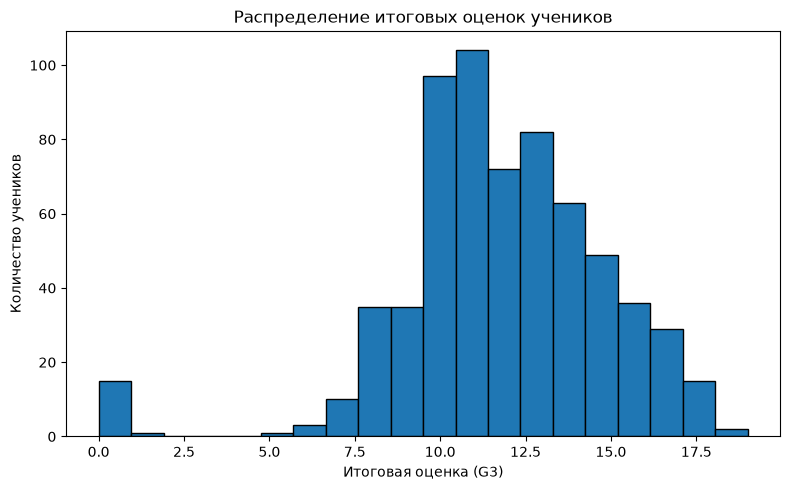

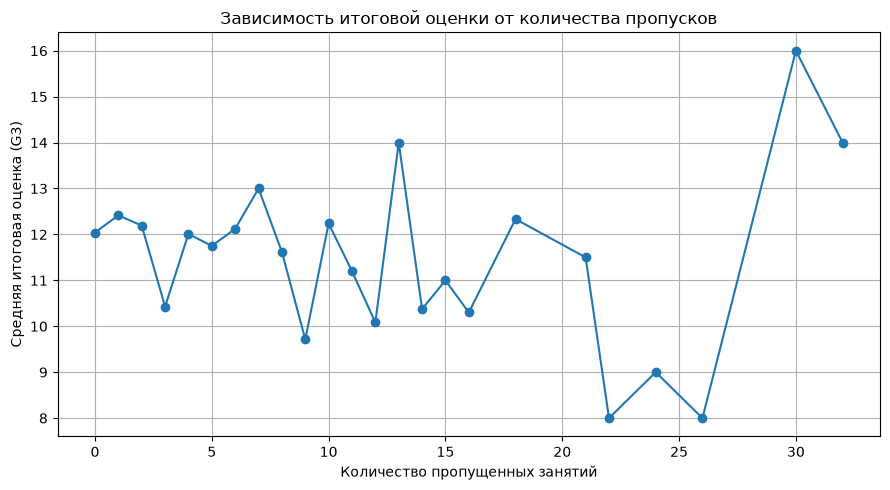

In [8]:

import matplotlib.pyplot as plt

# Настройка русского языка
plt.rcParams["font.family"] = "DejaVu Sans"

# График 1. Распределение итоговых оценок G3
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=20, edgecolor="black")
plt.title("Распределение итоговых оценок учеников")
plt.xlabel("Итоговая оценка (G3)")
plt.ylabel("Количество учеников")
plt.tight_layout()
plt.savefig("../figures/g9_g3_distribution.png", dpi=300)
plt.show()


# График 2. Средняя оценка в зависимости от пропусков
absences_mean = df.groupby("absences")["G3"].mean()

plt.figure(figsize=(9, 5))
plt.plot(absences_mean.index, absences_mean.values, marker="o")
plt.title("Зависимость итоговой оценки от количества пропусков")
plt.xlabel("Количество пропущенных занятий")
plt.ylabel("Средняя итоговая оценка (G3)")
plt.grid(True)
plt.tight_layout()
plt.savefig("../figures/g9_absences_vs_g3.png", dpi=300)
plt.show()


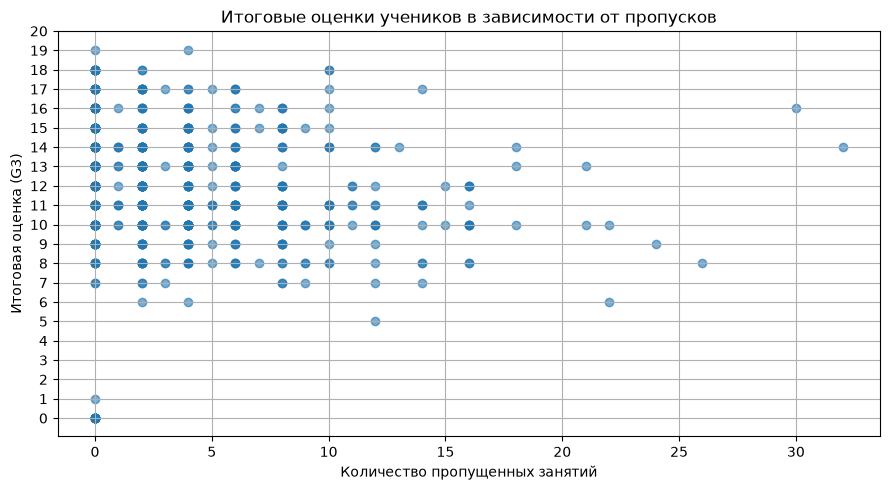

In [9]:

plt.figure(figsize=(9, 5))

plt.scatter(
    df["absences"],
    df["G3"],
    alpha=0.6
)

plt.title("Итоговые оценки учеников в зависимости от пропусков")
plt.xlabel("Количество пропущенных занятий")
plt.ylabel("Итоговая оценка (G3)")
plt.yticks(range(0, 21))
plt.grid(True)
plt.tight_layout()

plt.savefig("../figures/g9_individual_grades_absences.png", dpi=300)
plt.show()


In [13]:

results_table = pd.DataFrame({
    "Модель": ["Линейная регрессия", "Случайный лес"],
    "MAE (средняя абсолютная ошибка)": [
        linear_results["mae"], forest_results["mae"]
    ],
    "RMSE (корень из среднеквадратичной ошибки)": [
        linear_results["rmse"], forest_results["rmse"]
    ],
    "R² (коэффициент детерминации)": [
        linear_results["r2"], forest_results["r2"]
    ]
})

display(results_table.round(3))


display(results_table.round(3))

display(results_table.round(3))

,Модель,MAE (средняя абсолютная ошибка),RMSE (корень из среднеквадратичной ошибки),R² (коэффициент детерминации)
0,Линейная регрессия,2.235,2.953,0.211
1,Случайный лес,2.146,2.870,0.255


,Модель,MAE (средняя абсолютная ошибка),RMSE (корень из среднеквадратичной ошибки),R² (коэффициент детерминации)
0,Линейная регрессия,2.235,2.953,0.211
1,Случайный лес,2.146,2.870,0.255


,Модель,MAE (средняя абсолютная ошибка),RMSE (корень из среднеквадратичной ошибки),R² (коэффициент детерминации)
0,Линейная регрессия,2.235,2.953,0.211
1,Случайный лес,2.146,2.870,0.255
